In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [37]:
# Loading dataset 
df = pd.read_csv(r"C:\Users\Tanguy\Documents\IRONHACK\Week5\Day1\amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [38]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [39]:
#Frequency Tables:

#Generate a frequency table for the product category.

category_counts = df['category'].value_counts()
category_counts


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [40]:
#Which are the top 5 most listed product categories?
top_5_categories = category_counts.head(5)
print(top_5_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


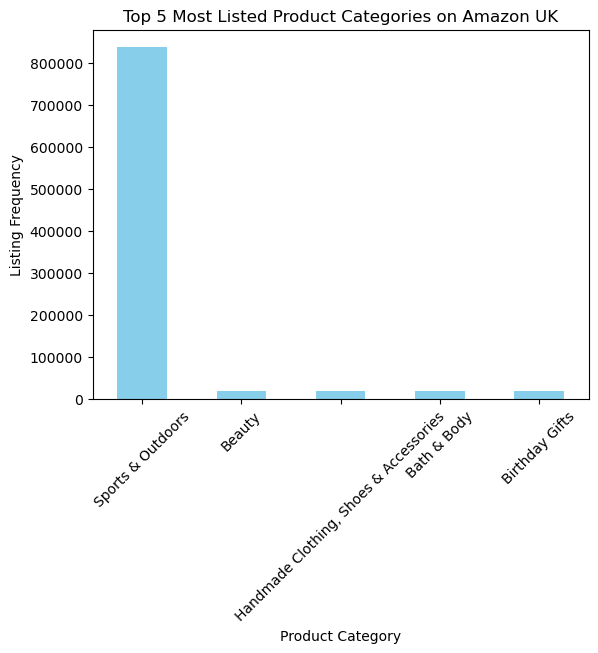

In [41]:
#2.Visualizations:

#2.1 Display the distribution of products across different categories using a bar chart. 
#If you face problems understanding the chart, do it for a subset of top categories.

top_5_categories.plot(kind='bar', color='skyblue')

plt.title('Top 5 Most Listed Product Categories on Amazon UK')
plt.xlabel('Product Category')
plt.ylabel('Listing Frequency')
plt.xticks(rotation=45)  # Rotate category labels for readability
plt.show()

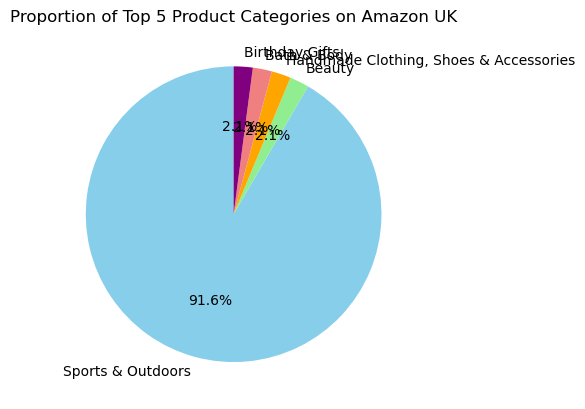

In [42]:
#2.2 For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
# Plot pie chart for the top categories
top_5_categories.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen', 'orange', 'lightcoral', 'purple'])

plt.title('Proportion of Top 5 Product Categories on Amazon UK')
plt.ylabel('')  # Remove y-label for a cleaner pie chart
plt.show()

Does any category dominate the listings?

The category sports & outdors is the one getting the 91.6 % of frequency, which gould be probably the most popular. 

In [44]:
#Part 2: Delving into Product Pricing
#Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?
#Measures of Centrality:

#Calculate the mean, median, and mode for the price of products.


mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Mode Price: {mode_price}")

Mean Price: 89.24380943923663
Median Price: 19.09
Mode Price: 9.99


Mean Price (89.24): The average price of products on Amazon UK is relatively high, suggesting there are some products with much higher prices pulling the average up.

Median Price (19.09): The median is much lower than the mean, meaning that 50% of the products are priced at or below 19.09. This suggests that most products are in the lower price range, but there are some high-priced products skewing the mean upwards.

Mode Price (9.99): The most common price point is 9.99, indicating that many products are priced around this point, likely representing affordable or lower-end products.

Insights:
The difference between the mean and median suggests that the data is positively skewed, meaning there are some high-priced products that are inflating the average.
The mode being the lowest value shows that lower-priced items (such as 9.99) dominate the listings, but there are also some high-end products which shift the mean up.

In [46]:
### 2.Measures of Dispersion:

#Determine the variance, standard deviation, range, and interquartile range for product price.
#How varied are the product prices? Are there any indicators of a significant spread in prices?


price_variance = df['price'].var()
price_std = df['price'].std()
price_range = df['price'].max() - df['price'].min()
price_iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Variance: {price_variance}")
print(f"Standard Deviation: {price_std}")
print(f"Range: {price_range}")
print(f"Interquartile Range: {price_iqr}")


Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range: 36.0


Variance (119,445.49):
This large variance shows that there is significant variability in the prices of products on Amazon UK, indicating that some products are priced much higher or lower than the average price.

Standard Deviation (345.61):
This standard deviation means that there are some products that are priced much higher than the average, contributing to the spread in the data.

Range (100,000):
The range is extremely large. This ptobably shows the presence of outliers or very high-priced products that are distorting the price distribution.

Interquartile Range (36):
This smaller IQR indicates that, although there are very high-priced items, most of the prices are within a relatively narrow range.

The large variance, standard deviation, and range suggest that prices vary widely, with a few high-priced items skewing the distribution.
The smaller interquartile range shows that most products are priced within a much narrower band, likely closer to the median and mode.

In [48]:
#3. Visualizations:

#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. 
#If its hard to read these diagrams, think why this is, and explain how it could be solved..
#Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread 
#and potential outliers in product pricing.

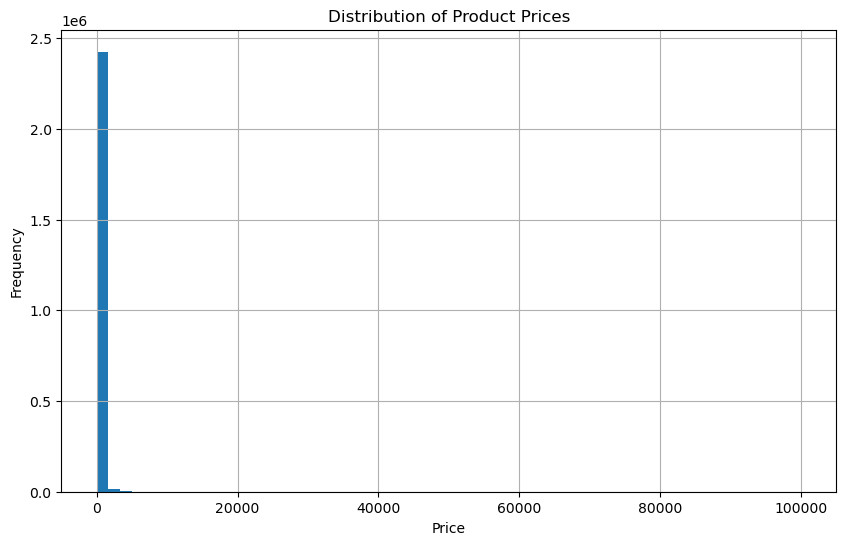

In [49]:
plt.figure(figsize=(10,6))
df['price'].hist(bins=60)
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

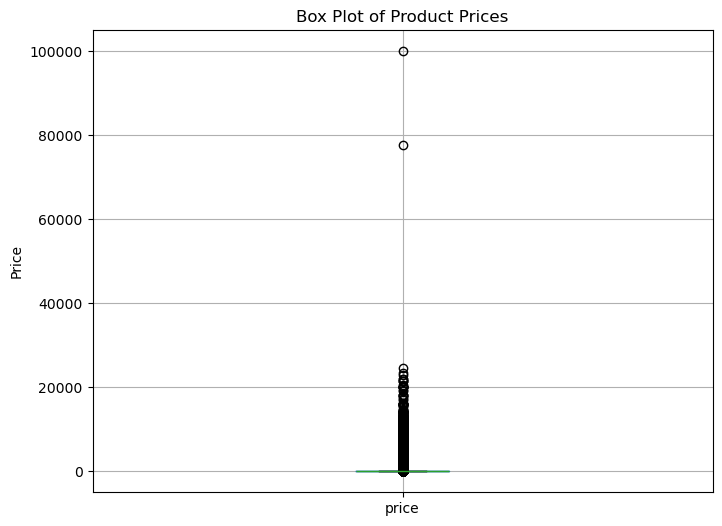

In [50]:
plt.figure(figsize=(8,6))
df.boxplot(column='price')
plt.title("Box Plot of Product Prices")
plt.ylabel("Price")
plt.show()

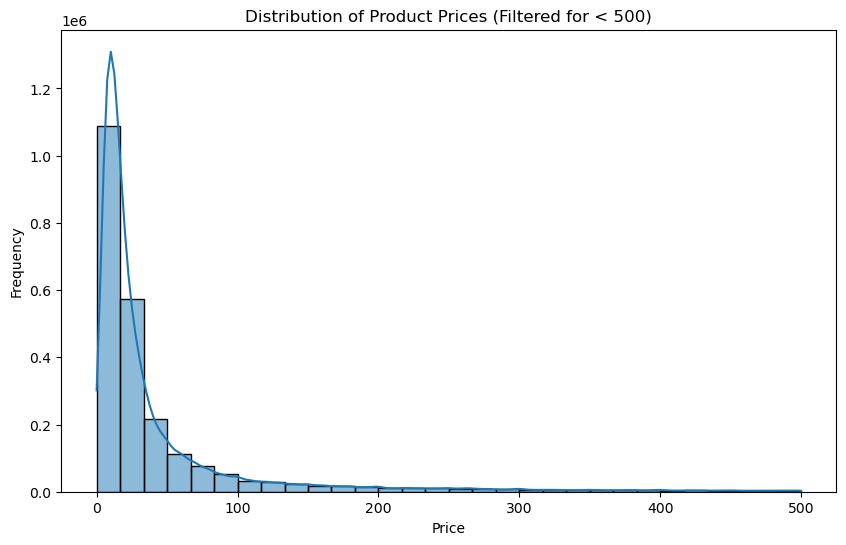

In [53]:
# Filter prices less than 500
filtered_prices = df[df['price'] < 500]['price']

# Tracer l'histogramme
plt.figure(figsize=(10, 6))
sns.histplot(filtered_prices, bins=30, kde=True)
plt.title('Distribution of Product Prices (Filtered for < 500)')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# Filter prices <1000
filtered_prices = df[df['price'] < 1000]['price']

# Tracer la boxplot avec prix filtrés
plt.figure(figsize=(10, 6))
sns.boxplot(x=filtered_prices)
plt.title('Boxplot of Product Prices (Filtered for < 1000)')
plt.xlabel('Price')
plt.show()

In [ ]:
# Calculate quantile
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Filter prices in IQR
iqr_filtered_prices = df[(df['price'] >= Q1 - 1.5 * IQR) & (df['price'] <= Q3 + 1.5 * IQR)]['price']

# plotting
plt.figure(figsize=(10, 6))
sns.boxplot(x=iqr_filtered_prices)
plt.title('Boxplot of Product Prices (Zoomed into IQR)')
plt.xlabel('Price')
plt.show()

In [ ]:
##Part 3: Unpacking Product Ratings
#Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

#Measures of Centrality:

#Calculate the mean, median, and mode for the rating of products.
#How do customers generally rate products? Is there a common trend?


# Calcul de la moyenne, médiane et mode pour les évaluations (ratings)
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]  # mode() retourne une série, on prend la première valeur

print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating: {mode_rating}")

Mean Rating (2.15): The average rating across all products is quite low, which suggests that many products have received lower scores from customers.

Median Rating (0.0): A median of 0 implies that at least half of the products in the dataset have either no ratings or very low ratings. 

Mode Rating (0.0): The most frequent rating is also 0, which further suggests that a significant portion of the products has not been rated or was given the lowest possible rating.

If the rating system uses 0 as a valid score (as opposed to "no rating"), then this would suggest that customers are consistently dissatisfied with the products listed.


In [ ]:
#2.
#Measures of Dispersion:

#Determine the variance, standard deviation, and interquartile range for product rating.
#Are the ratings consistent, or is there a wide variation in customer feedback?
# Calcul de la variance, écart-type et IQR pour les évaluations
variance_rating = df['stars'].var()
std_dev_rating = df['stars'].std()
iqr_rating = df['stars'].quantile(0.75) - df['stars'].quantile(0.25)

print(f"Variance Rating: {variance_rating}")
print(f"Standard Deviation Rating: {std_dev_rating}")
print(f"IQR Rating: {iqr_rating}")


Variance (4.82): This variance suggests that there is some variability in the ratings among the products, but it’s not excessively high.

Standard Deviation (2.19): This value means that ratings are spread out, with many products rated significantly different from the average. This suggests a moderate level of inconsistency in customer ratings.

Interquartile Range (IQR) (4.4): There is a noticeable spread in the central ratings, suggesting that while there are extreme ratings (especially low ones), the majority of products are rated within this range.


The moderate standard deviation suggests that while there are some products receiving low ratings, there are also products that may receive higher ratings, leading to a spread in the data.


In [ ]:
#3.
#Shape of the Distribution:

#Calculate the skewness and kurtosis for the rating column.
#Are the ratings normally distributed, or do they lean towards higher or lower values?

from scipy.stats import skew, kurtosis

# Calcule skewness and kurtosis 
skewness_rating = skew(df['stars'].dropna())
kurtosis_rating = kurtosis(df['stars'].dropna())

print(f"Skewness Rating: {skewness_rating}")
print(f"Kurtosis Rating: {kurtosis_rating}")


1. Skewness (0.0812):
This value shows that the distribution of product ratings is very close to symmetrical.
Since the skewness is close to zero, it suggests that there are no significant tendencies towards higher or lower values in the ratings.
2. Kurtosis (-1.9260):
This value shows that it has lighter tails and a flatter peak compared to a normal distribution.
This suggests that the ratings are more evenly distributed and that there are fewer extreme values 

The ratings appear to be fairly evenly distributed across the rating scale, with no significant bias toward high or low ratings.
The flatter distribution indicates that most products have ratings that are moderate rather than extreme.

In [ ]:
# Plotting the histogram of product ratings
plt.figure(figsize=(10, 6))
plt.hist(df['stars'], bins=10, color='blue', alpha=0.7, edgecolor='black')
plt.title('Distribution of Product Ratings on Amazon UK')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.xticks([0, 1, 2, 3, 4, 5])
plt.grid(axis='y', alpha=0.75)
plt.show()

In [ ]:
#
#4.
#Visualizations:

#Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], bins=20, kde=True)
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

Rating cero is the most common 